<a href="https://colab.research.google.com/github/GinaMCV/S8.01.-Anal-tica-de-datos-en-Pandas/blob/main/S8_01_nivel_3_Anal%C3%ADtica_de_datos_en_Pandas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 Importacion de librerias

In [23]:
import os
import re
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from IPython.display import Image, display

# Nivel 3 – Exploración visual y optimización aplicada
En este nivel se trabaja con un dataset ya rico y complejo, con múltiples variables personales, salariales, contextuales y derivadas. El objetivo no es seguir limpiando datos, sino extraer valor rápidamente y aplicar el dataset a un problema práctico.

El nivel se divide en dos ejercicios:

- » Exploración visual automatizada, para obtener una visión global del dataset, detectar patrones, anomalías o relaciones relevantes sin análisis manual exhaustivo.
- » Resolución de un problema aplicado, donde los datos sirven como soporte para tomar decisiones operativas reales, aunque la solución no sea matemáticamente óptima.

El foco está en el criterio analítico, la capacidad de síntesis y la justificación de decisiones, no en la perfección técnica.

#Ejercicio 1: Exploración visual del dataset
🌍 Contexto: Se dispone de un DataFrame con un volumen elevado de variables. Antes de cualquier análisis específico, es necesario disponer de mecanismos que permitan explorar el dataset de forma rápida y sistemática.

Este ejercicio se centra en crear una función que ayude a crear (y exportar) un gráfico automáticamente para cada columna del dataframe. Por ejemplo, un histograma/boxplot si la variable es numérica, unas barras de los valores más frecuentes si es categórica y unas barras de los años más frecuentes si el dato está en formato fecha.

## 1. La función de exploración automática

**Criterio de detección por columna** :
1. **Fecha** (`datetime64`) → barras con la frecuencia de cada año.
2. **Booleana** → se trata como categórica (barras de `True`/`False`)
3. **Numérica** histograma + boxplot, en la misma figura.
4. **Categórica / texto**  barras horizontales con los valores más frecuentes (se limita a un top N para no saturar el gráfico si hay muchas categorías distintas).

Columnas completamente vacías se detectan y se saltan, y se avisa en el resumen en vez de fallar.

In [24]:
def _nombre_archivo(texto):
    """Convierte el nombre de una columna en un nombre de archivo seguro (sin espacios ni acentos raros)."""
    return re.sub(r"[^a-zA-Z0-9_]+", "_", str(texto)).strip("_")


In [25]:
def explorar_dataframe(df, carpeta_salida="exploracion", top_n_categorias=12):
    """
    Genera y exporta un gráfico PNG por cada columna de `df`, eligiendo automáticamente
    el tipo de gráfico según el tipo de dato detectado.

    Parámetros
    ----------
    df : pd.DataFrame
        El DataFrame a explorar.
    carpeta_salida : str
        Carpeta donde se guardan los PNG (se crea si no existe).
    top_n_categorias : int
        Nº máximo de categorías a mostrar en las columnas categóricas (el resto se resume en el título).

    Devuelve
    --------
    pd.DataFrame con una fila por columna: tipo detectado, % de nulos y ruta del archivo generado.
    """
    os.makedirs(carpeta_salida, exist_ok=True)
    resumen = []

    for i, columna in enumerate(df.columns):
        serie = df[columna]
        pct_nulos = serie.isna().mean() * 100
        serie_valida = serie.dropna()

        if serie_valida.empty:
            resumen.append({"columna": columna, "tipo_detectado": "vacía (100% nulos)", "% nulos": 100.0, "archivo": None})
            continue

        es_fecha = pd.api.types.is_datetime64_any_dtype(serie)
        es_booleana = pd.api.types.is_bool_dtype(serie)
        es_numerica = pd.api.types.is_numeric_dtype(serie) and not es_booleana

        if es_fecha:
            tipo = "fecha"
            fig, ax = plt.subplots(figsize=(6, 4))
            conteo = serie_valida.dt.year.value_counts().sort_index()
            ax.bar(conteo.index.astype(str), conteo.values, color="#4C72B0")
            ax.set_title(f"{columna} — años más frecuentes")
            ax.set_xlabel("Año"); ax.set_ylabel("Frecuencia")
            plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

        elif es_numerica:
            tipo = "numérica"
            fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4))
            sns.histplot(serie_valida, kde=True, ax=ax1, color="#4C72B0")
            ax1.set_title(f"{columna} — histograma")
            sns.boxplot(x=serie_valida, ax=ax2, color="#DD8452")
            ax2.set_title(f"{columna} — boxplot")

        else:
            tipo = "booleana" if es_booleana else "categórica"
            conteo = serie_valida.astype(str).value_counts()
            truncado = len(conteo) > top_n_categorias
            conteo_mostrar = conteo.head(top_n_categorias)

            fig, ax = plt.subplots(figsize=(6, max(3, 0.4 * len(conteo_mostrar) + 1)))
            sns.barplot(x=conteo_mostrar.values, y=conteo_mostrar.index, ax=ax, color="#55A868")
            titulo = f"{columna} — valores más frecuentes"
            if truncado:
                titulo += f"  (top {top_n_categorias} de {len(conteo)} categorías)"
            ax.set_title(titulo)
            ax.set_xlabel("Frecuencia"); ax.set_ylabel("")

        if pct_nulos > 0:
            fig.suptitle(f"{pct_nulos:.1f}% de valores nulos en esta columna", fontsize=9, color="gray")
        fig.tight_layout()

        nombre_archivo = f"{i:02d}_{tipo}_{_nombre_archivo(columna)}.png"
        ruta = os.path.join(carpeta_salida, nombre_archivo)
        fig.savefig(ruta, dpi=110, bbox_inches="tight")
        plt.close(fig)

        resumen.append({"columna": columna, "tipo_detectado": tipo, "% nulos": round(pct_nulos, 1), "archivo": ruta})

    return pd.DataFrame(resumen)

## 2. Demostración sobre `titanic` (seaborn)

Un dataset con mezcla de numéricas, categóricas y booleanas

In [26]:
titanic = sns.load_dataset("titanic")
print("Dimensiones:", titanic.shape)
display(titanic.head(3))
print("\nTipos de columna:")
print(titanic.dtypes)

Dimensiones: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True



Tipos de columna:
survived          int64
pclass            int64
sex              object
age             float64
sibsp             int64
parch             int64
fare            float64
embarked         object
class          category
who              object
adult_male         bool
deck           category
embark_town      object
alive            object
alone              bool
dtype: object


## Resumen
- De las 15 columnas, la función detecta automáticamente 6 numéricas, 7 categóricas y 2 booleanas (`adult_male`, `alone`)
- La columna `deck` aparece con un 77,2 % de nulos: se avisa en el título del propio gráfico, en vez de ocultarlo.

In [27]:
resumen_titanic = explorar_dataframe(titanic, carpeta_salida="exploracion_titanic")
display(resumen_titanic)

,columna,tipo_detectado,% nulos,archivo
0,survived,numérica,0.0,exploracion_titanic/00_numérica_survived.png
1,pclass,numérica,0.0,exploracion_titanic/01_numérica_pclass.png
2,sex,categórica,0.0,exploracion_titanic/02_categórica_sex.png
3,age,numérica,19.9,exploracion_titanic/03_numérica_age.png
4,sibsp,numérica,0.0,exploracion_titanic/04_numérica_sibsp.png
5,parch,numérica,0.0,exploracion_titanic/05_numérica_parch.png
6,fare,numérica,0.0,exploracion_titanic/06_numérica_fare.png
7,embarked,categórica,0.2,exploracion_titanic/07_categórica_embarked.png
8,class,categórica,0.0,exploracion_titanic/08_categórica_class.png
9,who,categórica,0.0,exploracion_titanic/09_categórica_who.png


### 2.1 Todos los gráficos generados

survived  (numérica)


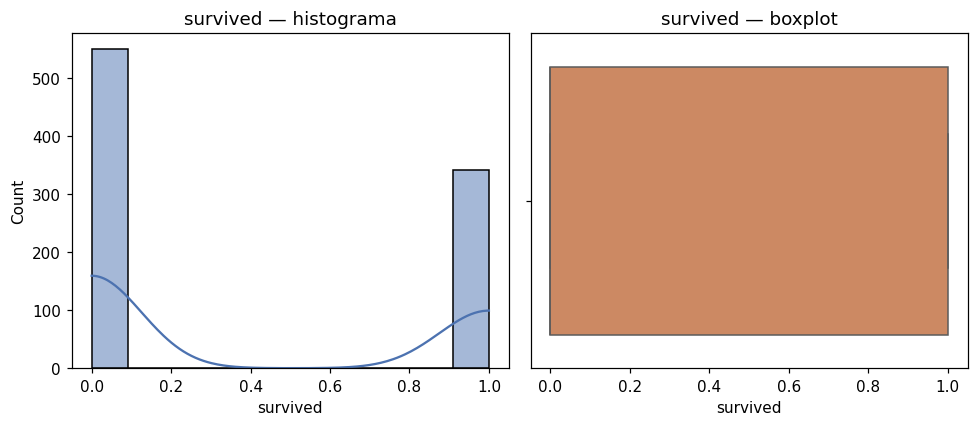

pclass  (numérica)


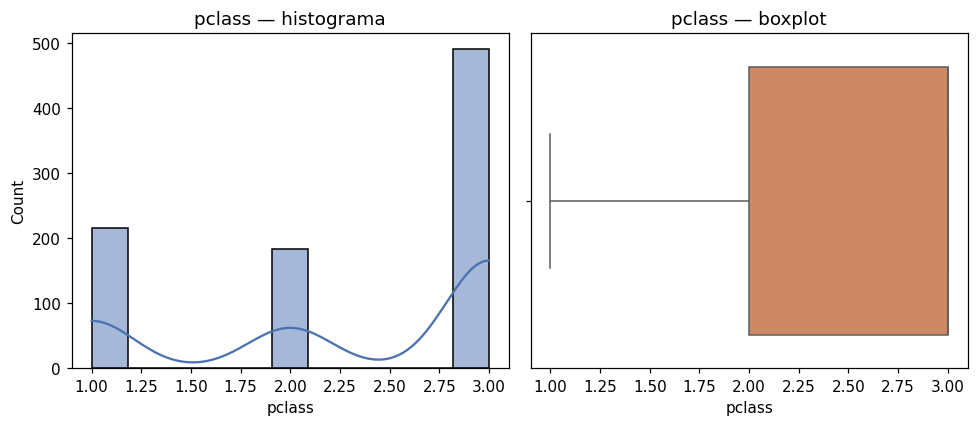

sex  (categórica)


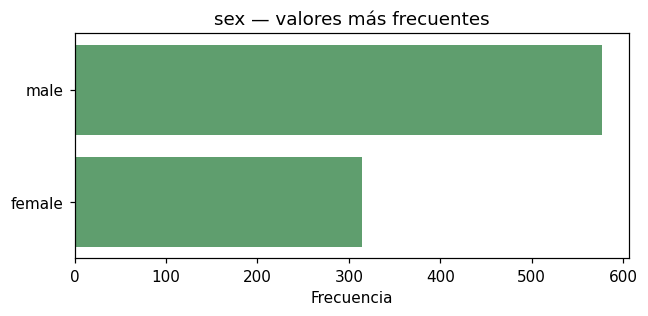

age  (numérica)


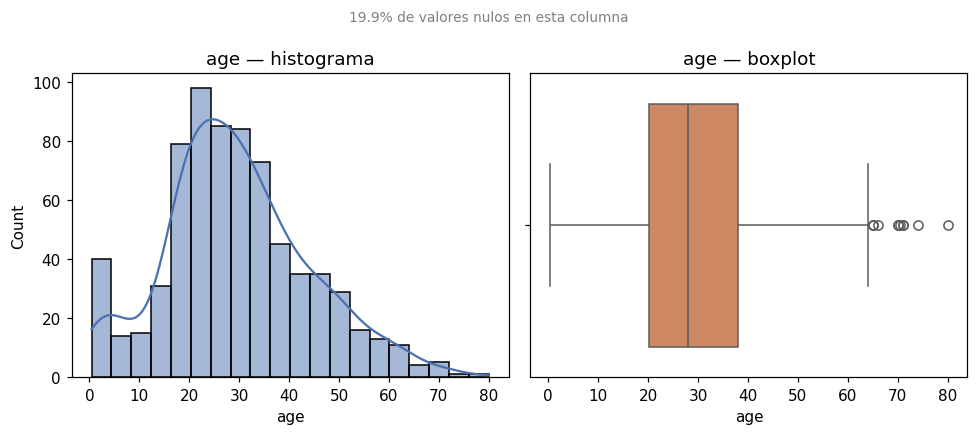

sibsp  (numérica)


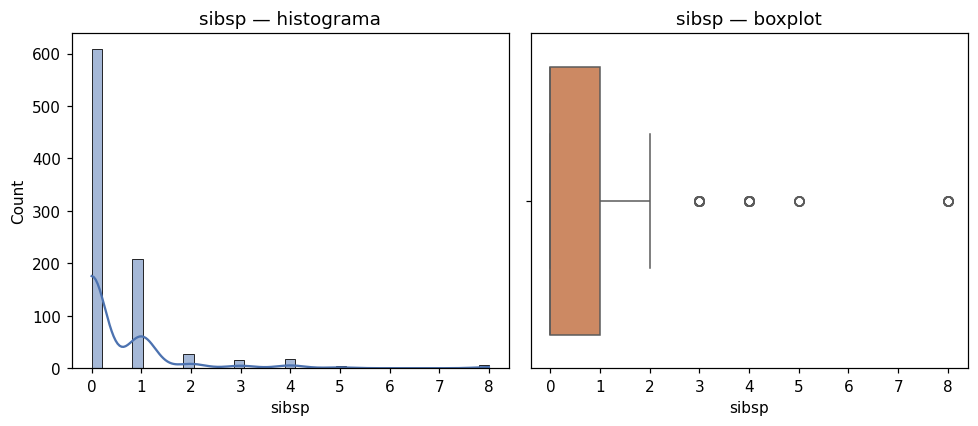

parch  (numérica)


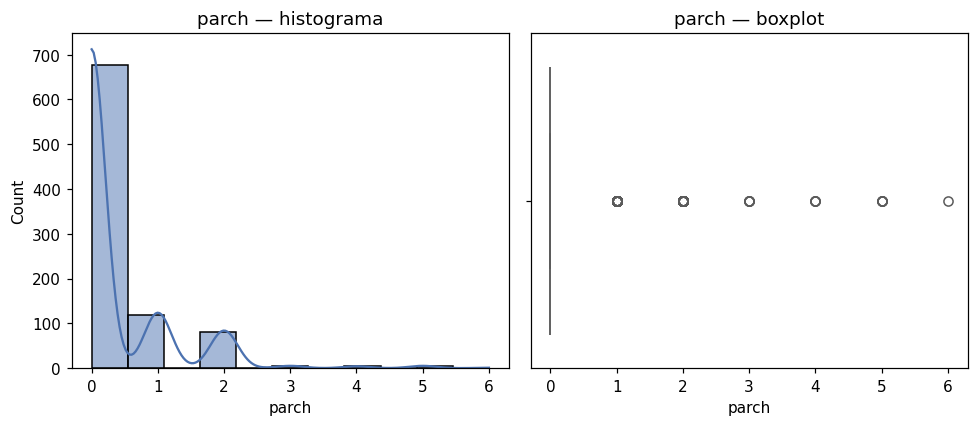

fare  (numérica)


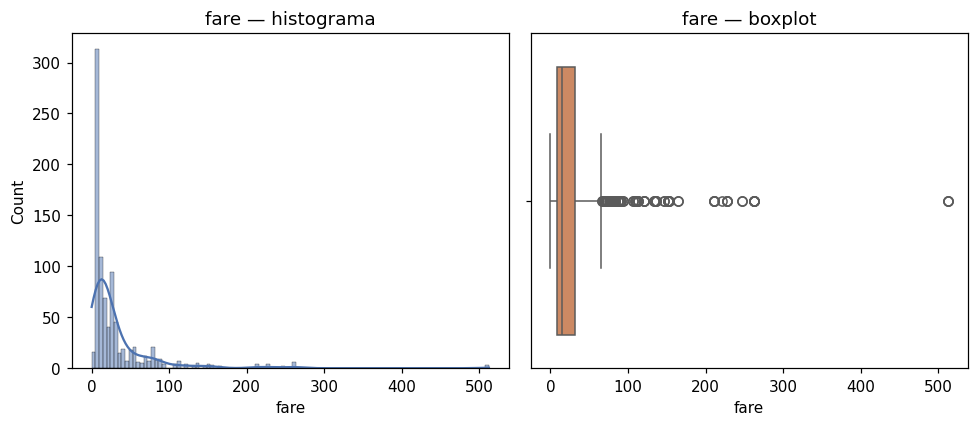

embarked  (categórica)


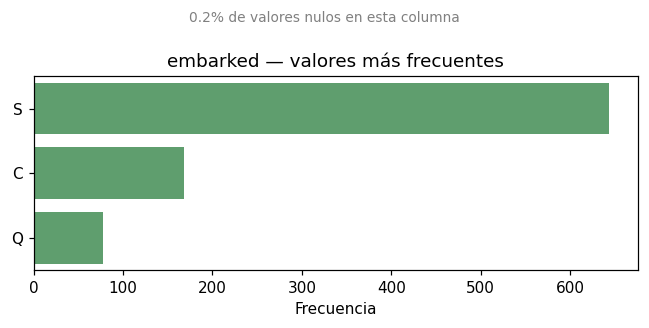

class  (categórica)


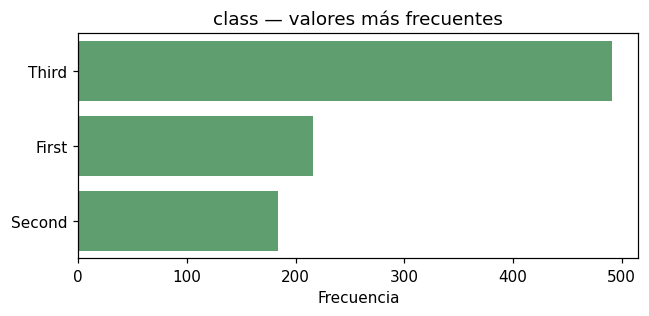

who  (categórica)


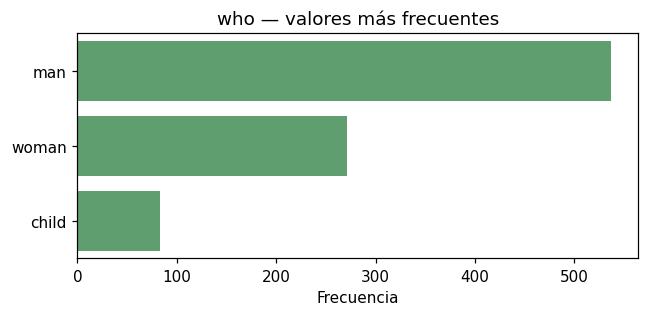

adult_male  (booleana)


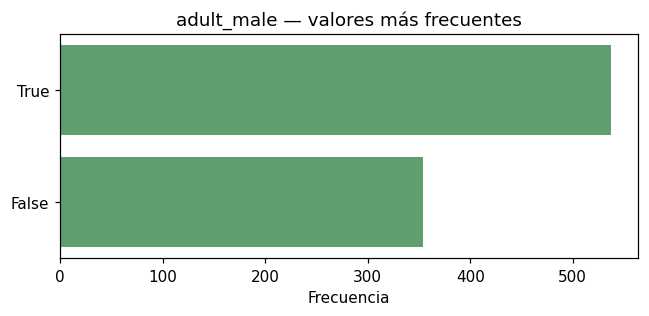

deck  (categórica)


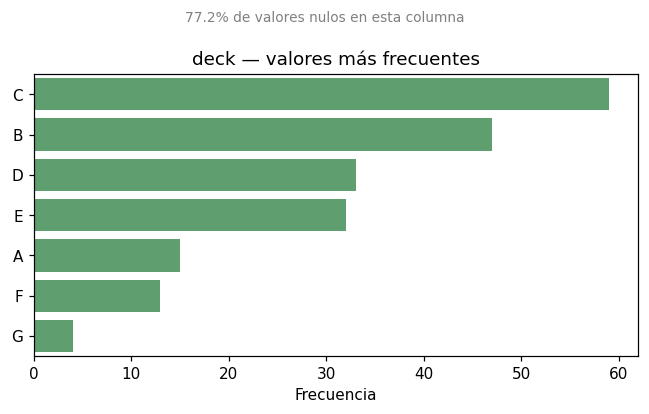

embark_town  (categórica)


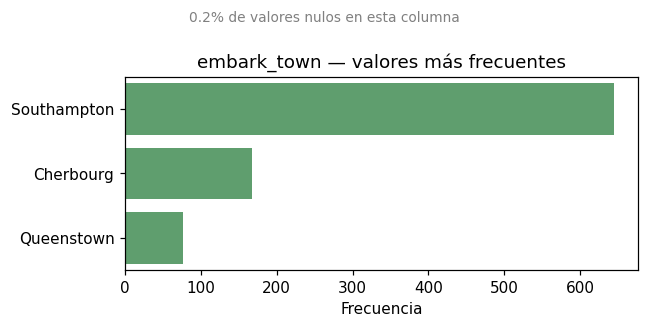

alive  (categórica)


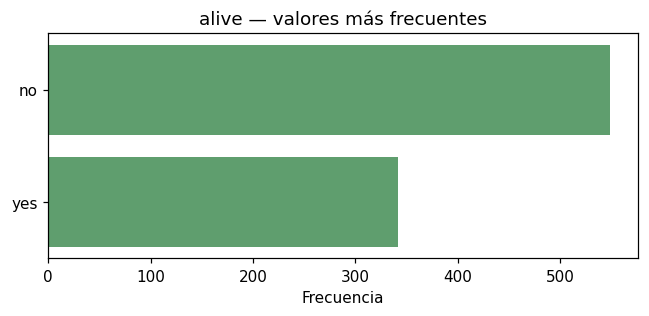

alone  (booleana)


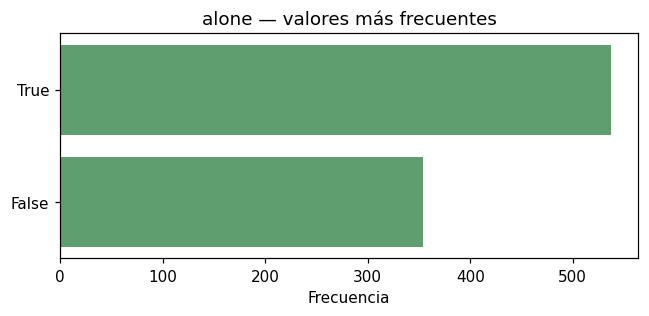

In [28]:
for _, fila in resumen_titanic.dropna(subset=["archivo"]).iterrows():
    print(f"{fila['columna']}  ({fila['tipo_detectado']})")
    display(Image(filename=fila["archivo"]))

#Ejercicio 2: Optimización de rutas (problema aplicado)
🌍 Contexto: La empresa no dispone de un control fiable del kilometraje de los desplazamientos de sus trabajadores. Antes de implementar un sistema avanzado, se quiere realizar una prueba piloto con trabajadores ubicados en España.
Para esta prueba:

» Se trabaja con una matriz de distancias entre ciudades.
» Se quiere una solución simple, razonable y explicable.
» No se busca la ruta óptima, sino una aproximación coherente.
Carga el archivo matriu_distancies.xlsxa pandas de modo que las filas y columnas sean las ciudades y se eliminen " Las Palmas de Gran Canaria " y " Palma ".

Desarrolla una función que:

» Reciba: una ciudad de origen y una ciudad de destino.
» Regreso: el orden de las ciudades visitadas (ruta) y la distancia total recorrida.

In [29]:
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

matriz = pd.read_excel("/content/drive/MyDrive/Colab Notebooks/phyton_especialidad/matriu_distancies.xlsx", index_col=0)
display(matriz)

,Barcelona,Valencia,Sevilla,Zaragoza,Málaga,Murcia,Palma,Las Palmas de Gran Canaria,Bilbao,Alicante,Córdoba,Valladolid,Vigo,Gijón,Hospitalet de Llobregat
Barcelona,NaN,303.0,831.0,256.0,770.0,471.0,206.0,2175.0,469.0,407.0,711.0,576.0,908.0,686.0,7.0
Valencia,303.0,NaN,541.0,246.0,468.0,177.0,260.0,1874.0,473.0,125.0,421.0,441.0,766.0,632.0,297.0
Sevilla,831.0,541.0,NaN,646.0,158.0,433.0,791.0,1355.0,703.0,495.0,121.0,486.0,588.0,685.0,824.0
Zaragoza,256.0,246.0,646.0,NaN,628.0,408.0,377.0,2001.0,246.0,368.0,535.0,320.0,652.0,444.0,250.0
Málaga,770.0,468.0,158.0,628.0,NaN,323.0,695.0,1406.0,739.0,391.0,133.0,549.0,716.0,766.0,763.0
Murcia,471.0,177.0,433.0,408.0,323.0,NaN,372.0,1723.0,606.0,69.0,320.0,510.0,800.0,726.0,465.0
Palma,206.0,260.0,791.0,377.0,695.0,372.0,NaN,2093.0,621.0,303.0,671.0,664.0,1000.0,820.0,204.0
Las Palmas de Gran Canaria,2175.0,1874.0,1355.0,2001.0,1406.0,1723.0,2093.0,NaN,2022.0,1792.0,1470.0,1790.0,1682.0,1925.0,2168.0
Bilbao,469.0,473.0,703.0,246.0,739.0,606.0,621.0,2022.0,NaN,583.0,618.0,232.0,486.0,223.0,465.0
Alicante,407.0,125.0,495.0,368.0,391.0,69.0,303.0,1792.0,583.0,NaN,379.0,515.0,821.0,722.0,401.0


### Eliminar las ciudades insulares
`Las Palmas de Gran Canaria` y `Palma` son las únicas dos ciudades insulares de la matriz (Canarias y Baleares); el resto son todas peninsulares.

La prueba piloto solo cubre trabajadores en la España peninsular, así que no tiene sentido que la ruta "por carretera" pase por ellas

In [30]:
CIUDADES_A_EXCLUIR = ["Las Palmas de Gran Canaria", "Palma"]

matriz = matriz.drop(index=CIUDADES_A_EXCLUIR, columns=CIUDADES_A_EXCLUIR)

print("Matriz tras eliminar las ciudades insulares:", matriz.shape)
print("Ciudades:", matriz.index.tolist())
print("\n¿Es simétrica (distancia A→B = distancia B→A)?", (matriz.fillna(0) == matriz.T.fillna(0)).all().all())
print("¿Tiene huecos además de la propia diagonal?", matriz.isna().sum().sum() - len(matriz), "(0 = la matriz está completa)")

Matriz tras eliminar las ciudades insulares: (13, 13)
Ciudades: ['Barcelona', 'Valencia', 'Sevilla', 'Zaragoza', 'Málaga', 'Murcia', 'Bilbao', 'Alicante', 'Córdoba', 'Valladolid', 'Vigo', 'Gijón', 'Hospitalet de Llobregat']

¿Es simétrica (distancia A→B = distancia B→A)? True
¿Tiene huecos además de la propia diagonal? 0 (0 = la matriz está completa)


## 1. La función de ruta: vecino más cercano

**Estrategia:** partiendo de la ciudad de origen, en cada paso se mueve a la ciudad **no visitada** más cercana a la ciudad actual, y se repite hasta llegar al destino.

In [31]:
def ruta_vecino_mas_cercano(matriz, origen, destino):
    """
    Construye una ruta de `origen` a `destino` moviéndose siempre a la ciudad no visitada
    más cercana a la ciudad actual, hasta llegar al destino.

    Parámetros
    ----------
    matriz : pd.DataFrame
        Matriz de distancias cuadrada (ciudades en filas y columnas, simétrica).
    origen, destino : str
        Nombres de ciudad, tal como aparecen en el índice/columnas de `matriz`.

    Devuelve
    --------
    (ruta, distancia_total) : (list[str], float)
        `ruta` es la lista ordenada de ciudades visitadas (incluye origen y destino).
        `distancia_total` es la suma de los tramos recorridos, en las unidades de la matriz.
    """
    for ciudad in (origen, destino):
        if ciudad not in matriz.index:
            raise ValueError(f"'{ciudad}' no está en la matriz de distancias.")

    if origen == destino:
        return [origen], 0.0

    visitadas = [origen]
    actual = origen
    distancia_total = 0.0

    while actual != destino:
        candidatas = matriz.loc[actual].drop(index=visitadas, errors="ignore").dropna()
        if candidatas.empty:

            raise RuntimeError(f"No se puede llegar a '{destino}' desde '{actual}': no quedan ciudades conectadas sin visitar.")

        siguiente = candidatas.idxmin()
        distancia_total += candidatas.min()
        visitadas.append(siguiente)
        actual = siguiente

    return visitadas, round(distancia_total, 1)

## 2. Probando la función

In [32]:
rutas_de_prueba = [
    ("Barcelona", "Vigo"),
    ("Gijón", "Alicante"),
    ("Valencia", "Bilbao"),
    ("Sevilla", "Sevilla"),
]

for origen, destino in rutas_de_prueba:
    ruta, distancia = ruta_vecino_mas_cercano(matriz, origen, destino)
    print(f"{origen} → {destino}  ({len(ruta)} ciudades, {distancia} km)")
    print("  " + " → ".join(ruta))
    print()

Barcelona → Vigo  (13 ciudades, 2778.0 km)
  Barcelona → Hospitalet de Llobregat → Zaragoza → Valencia → Alicante → Murcia → Córdoba → Sevilla → Málaga → Valladolid → Gijón → Bilbao → Vigo

Gijón → Alicante  (6 ciudades, 1146.0 km)
  Gijón → Bilbao → Valladolid → Zaragoza → Valencia → Alicante

Valencia → Bilbao  (9 ciudades, 1789.0 km)
  Valencia → Alicante → Murcia → Córdoba → Sevilla → Málaga → Valladolid → Gijón → Bilbao

Sevilla → Sevilla  (1 ciudades, 0.0 km)
  Sevilla

